# Predicción de Cancelación de Reservas Hoteleras
### Un reto de clasificación con impacto directo en revenue management

**Máster en Data Science & IA — Evolve Academy**

---

## 1. Contexto de negocio

Trabajamos como data scientists para una cadena hotelera con dos propiedades en Portugal (un *City Hotel* y un *Resort Hotel*). El equipo de **Revenue Management** necesita anticipar, **en el momento de la reserva**, qué clientes tienen alta probabilidad de cancelar, para poder activar acciones preventivas:

- Ofrecer upgrades con descuento a clientes de bajo riesgo para fidelizar.
- Solicitar depósito no reembolsable de forma selectiva a clientes de alto riesgo.
- Ajustar la política de *overbooking* para minimizar habitaciones vacías de última hora.

**El coste de los errores no es simétrico:**
- Un **falso negativo** (predecir que no cancela y sí cancela) → habitación vacía a precio de coste, ingreso perdido.
- Un **falso positivo** (predecir cancelación y no cancela) → acción preventiva innecesaria que puede molestar a un cliente fiel.

Este notebook desarrolla el pipeline completo: EDA → limpieza → feature engineering → partición temporal → modelado → evaluación orientada a negocio → interpretabilidad (SHAP) → conclusiones.

**Dataset:** *Hotel Booking Demand* (Antonio, Almeida & Nunes, 2019) — ~119.000 reservas, 2 hoteles, julio 2015 – agosto 2017. Target: `is_canceled`.


In [1]:
# Instalar dependencias

%pip install -r requirements.txt

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# --- Librerías ---
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.metrics import (
    roc_auc_score, f1_score, precision_score, recall_score,
    precision_recall_curve, roc_curve, ConfusionMatrixDisplay,
    classification_report
)

from xgboost import XGBClassifier
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

import shap

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (9, 5)
RANDOM_STATE = 42

pd.set_option("display.max_columns", 50)


## 2. Carga de datos y primer vistazo

In [3]:
df = pd.read_csv("reservas_hoteleras.csv")
print("Dimensiones:", df.shape)
df.head()


Dimensiones: (119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [4]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

In [5]:
# Valores nulos por columna (solo las que tienen alguno)
nulos = df.isna().sum()
nulos = nulos[nulos > 0].sort_values(ascending=False)
pd.DataFrame({"n_nulos": nulos, "% nulos": (nulos / len(df) * 100).round(2)})


,n_nulos,% nulos
company,112593,94.31
agent,16340,13.69
country,488,0.41
children,4,0.00


**Observaciones iniciales:**
- `company` tiene ~94% de valores nulos → prácticamente no aporta información y su alta cardinalidad no compensa; la excluiremos.
- `agent` tiene ~14% de nulos → la transformaremos en una variable más simple y robusta (`booked_via_agent`).
- `country` tiene 488 nulos y 177 categorías distintas → alta cardinalidad, la agruparemos en las N principales + "Other".
- `children` tiene 4 nulos → los imputamos a 0 (asumimos que si no se especifica, no hay niños).


## 3. Limpieza de datos y eliminación de Data Leakage

### 3.1 Variables excluidas obligatoriamente por fuga de información

 Excluimos:

- **`reservation_status`**: contiene literalmente el resultado final (`Canceled`, `Check-Out`, `No-Show`). Es prácticamente el target disfrazado.
- **`reservation_status_date`**: fecha asociada al evento anterior, también posterior a la reserva.

Adicionalmente, tomamos una decisión de negocio defendible sobre una variable "gris":

- **`assigned_room_type`**: en muchos casos la habitación asignada se define cerca del check-in (p. ej. por overbooking o disponibilidad real), es decir, **después** del momento de la reserva que es cuando debe operar el modelo. La excluimos para evitar fuga temporal, y mantenemos `reserved_room_type` (la solicitada en el momento de reservar, que sí es válida).


In [6]:
LEAKAGE_COLS = ["reservation_status", "reservation_status_date", "assigned_room_type"]
df = df.drop(columns=LEAKAGE_COLS)
print("Columnas eliminadas por leakage:", LEAKAGE_COLS)
print("Dimensiones tras eliminar leakage:", df.shape)


Columnas eliminadas por leakage: ['reservation_status', 'reservation_status_date', 'assigned_room_type']
Dimensiones tras eliminar leakage: (119390, 29)


### 3.2 Limpieza de valores anómalos y nulos

In [7]:
# children nulo -> 0
df["children"] = df["children"].fillna(0)

# country nulo -> 'Unknown'
df["country"] = df["country"].fillna("Unknown")

# adr negativo (coste diario < 0 no tiene sentido de negocio) -> lo recortamos a 0
n_adr_neg = (df["adr"] < 0).sum()
df["adr"] = df["adr"].clip(lower=0)
print(f"Registros con adr negativo corregidos a 0: {n_adr_neg}")

# Reservas sin ningún huésped (adults + children + babies == 0) son inconsistentes -> las eliminamos
mask_sin_huespedes = (df["adults"] + df["children"] + df["babies"]) == 0
print(f"Reservas sin huéspedes eliminadas: {mask_sin_huespedes.sum()}")
df = df[~mask_sin_huespedes].reset_index(drop=True)

print("Dimensiones tras limpieza:", df.shape)


Registros con adr negativo corregidos a 0: 1
Reservas sin huéspedes eliminadas: 180
Dimensiones tras limpieza: (119210, 29)


In [8]:
# Reconstruimos la fecha de llegada (necesaria para el split temporal y el EDA estacional)
df["arrival_date"] = pd.to_datetime(
    df["arrival_date_year"].astype(str) + "-" +
    df["arrival_date_month"] + "-" +
    df["arrival_date_day_of_month"].astype(str),
    format="%Y-%B-%d"
)
print("Rango de fechas:", df["arrival_date"].min(), "→", df["arrival_date"].max())


Rango de fechas: 2015-07-01 00:00:00 → 2017-08-31 00:00:00


## 4. EDA y comprensión del negocio

Tasa global de cancelación:

Tasa de cancelación global: 37.1%


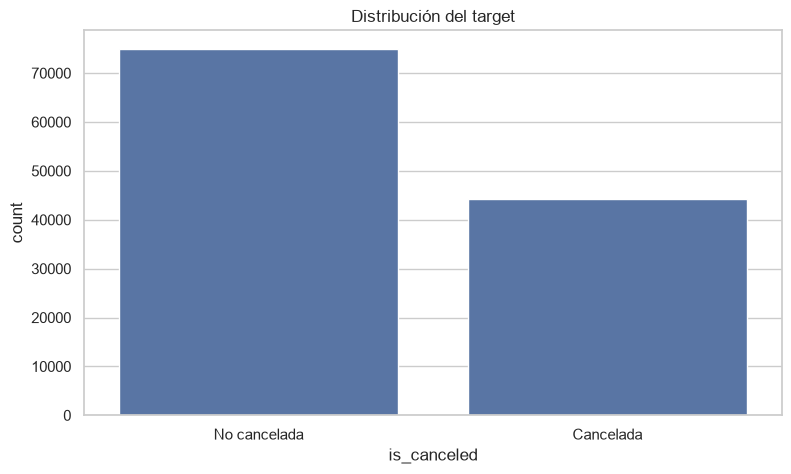

In [9]:
tasa_global = df["is_canceled"].mean()
print(f"Tasa de cancelación global: {tasa_global:.1%}")
sns.countplot(data=df, x="is_canceled")
plt.xticks([0, 1], ["No cancelada", "Cancelada"])
plt.title("Distribución del target")
plt.show()


### 4.1 Cancelaciones por hotel, mes y canal de distribución

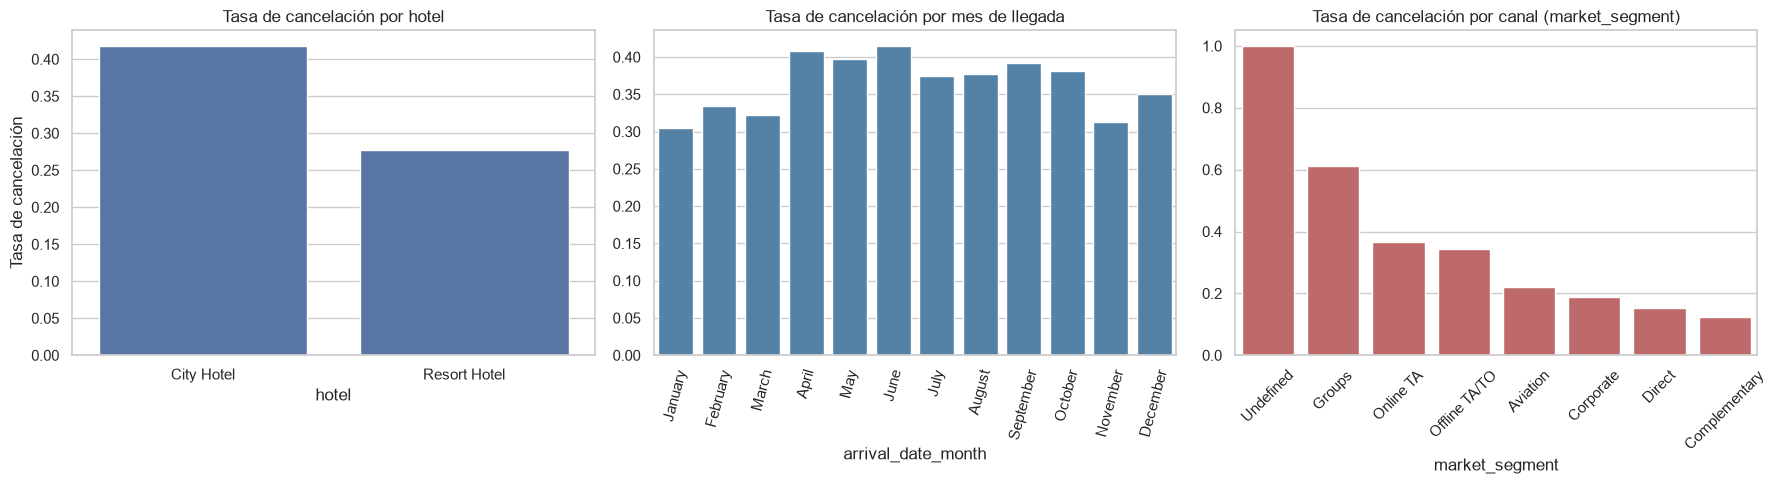

hotel
City Hotel      0.417859
Resort Hotel    0.277674
Name: is_canceled, dtype: float64 

market_segment
Undefined        1.000000
Groups           0.611086
Online TA        0.367590
Offline TA/TO    0.343313
Aviation         0.221277
Corporate        0.187618
Direct           0.153712
Complementary    0.122253
Name: is_canceled, dtype: float64


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Por hotel
tasa_hotel = df.groupby("hotel")["is_canceled"].mean().sort_values(ascending=False)
sns.barplot(x=tasa_hotel.index, y=tasa_hotel.values, ax=axes[0])
axes[0].set_title("Tasa de cancelación por hotel")
axes[0].set_ylabel("Tasa de cancelación")

# Por mes (ordenado cronológicamente)
orden_meses = ["January","February","March","April","May","June",
               "July","August","September","October","November","December"]
tasa_mes = df.groupby("arrival_date_month")["is_canceled"].mean().reindex(orden_meses)
sns.barplot(x=tasa_mes.index, y=tasa_mes.values, ax=axes[1], color="steelblue")
axes[1].set_title("Tasa de cancelación por mes de llegada")
axes[1].tick_params(axis="x", rotation=75)

# Por canal (market_segment)
tasa_canal = df.groupby("market_segment")["is_canceled"].mean().sort_values(ascending=False)
sns.barplot(x=tasa_canal.index, y=tasa_canal.values, ax=axes[2], color="indianred")
axes[2].set_title("Tasa de cancelación por canal (market_segment)")
axes[2].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

print(tasa_hotel, "\n")
print(tasa_canal)


**Conclusión accionable (4.1):** el *City Hotel* cancela notablemente más que el *Resort Hotel*, y los canales **Groups** y **Online TA** presentan tasas de cancelación muy superiores a **Direct** o **Corporate**. Además, los meses de temporada alta (verano) muestran picos de cancelación coincidiendo con mayor volumen de reservas especulativas.
→ **Acción de negocio:** priorizar el modelo de scoring y las políticas de depósito no reembolsable especialmente en reservas del City Hotel captadas vía agencias online o grupos, en lugar de aplicar una política uniforme a todo el inventario.


### 4.2 Relación entre `lead_time` y tasa de cancelación

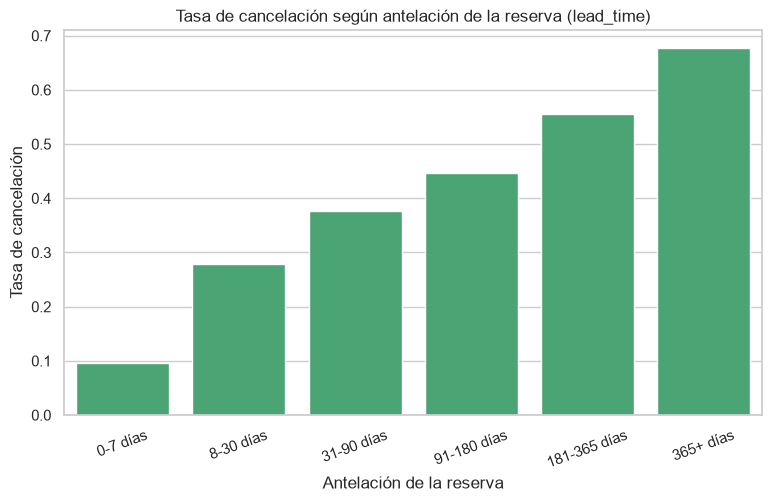

lead_time_bin
0-7 días        0.096002
8-30 días       0.278860
31-90 días      0.377290
91-180 días     0.447350
181-365 días    0.554565
365+ días       0.676517
Name: is_canceled, dtype: float64


In [11]:
df["lead_time_bin"] = pd.cut(
    df["lead_time"],
    bins=[-1, 7, 30, 90, 180, 365, df["lead_time"].max()],
    labels=["0-7 días", "8-30 días", "31-90 días", "91-180 días", "181-365 días", "365+ días"]
)

tasa_lead = df.groupby("lead_time_bin", observed=True)["is_canceled"].mean()

plt.figure()
sns.barplot(x=tasa_lead.index, y=tasa_lead.values, color="mediumseagreen")
plt.title("Tasa de cancelación según antelación de la reserva (lead_time)")
plt.ylabel("Tasa de cancelación")
plt.xlabel("Antelación de la reserva")
plt.xticks(rotation=20)
plt.show()

print(tasa_lead)


**Conclusión accionable (4.2):** la tasa de cancelación crece de forma prácticamente monótona con la antelación de la reserva: las reservas hechas con más de un año de antelación cancelan varias veces más que las de última hora.
→ **Acción de negocio:** el `lead_time` es candidato natural a "disparador" de reglas de negocio (p. ej. solicitar confirmación o depósito a reservas con antelación superior a 90-180 días), y esperamos que sea una de las variables más influyentes del modelo.


### 4.3 ADR medio: canceladas vs. no canceladas

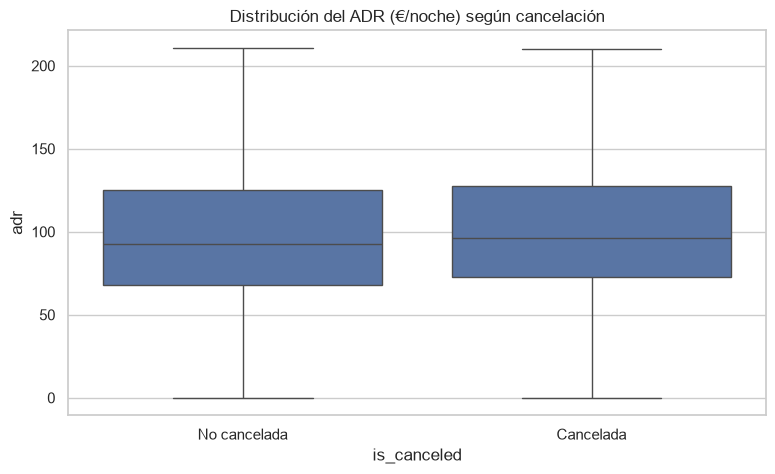

                   mean  median
is_canceled                    
0            100.169297    92.7
1            105.023703    96.3


In [12]:
plt.figure()
sns.boxplot(data=df, x="is_canceled", y="adr", showfliers=False)
plt.xticks([0, 1], ["No cancelada", "Cancelada"])
plt.title("Distribución del ADR (€/noche) según cancelación")
plt.show()

print(df.groupby("is_canceled")["adr"].agg(["mean", "median"]))


**Conclusión accionable (4.3):** las reservas canceladas tienen, en media, un ADR ligeramente **superior** a las que se completan. Esto es coherente con que las reservas más caras (o con tarifas flexibles) sean más fáciles de cancelar sin penalización, mientras que tarifas más económicas suelen ir asociadas a condiciones no reembolsables.
→ **Acción de negocio:** el precio por sí solo no es un gran discriminador, pero cruzado con `deposit_type` puede ayudar a decidir en qué reservas de tarifa alta conviene reforzar condiciones de cancelación.


## 5. Feature engineering

Construimos variables nuevas a partir de las existentes, cada una con su justificación de negocio.


In [13]:
# total_guests: tamaño total del grupo -> reservas más grandes pueden tener dinámicas de cancelación distintas
# (coordinación de varias personas, mayor probabilidad de que algún imprevisto cancele el plan grupal)
df["total_guests"] = df["adults"] + df["children"] + df["babies"]

# total_nights: duración total de la estancia -> estancias más largas implican mayor compromiso económico
# y logístico, lo que puede reducir la probabilidad de cancelar por impulso.
df["total_nights"] = df["stays_in_weekend_nights"] + df["stays_in_week_nights"]

# is_family: viaja con niños o bebés -> los viajes familiares suelen planificarse con más antelación
# y son menos flexibles (vacaciones escolares), lo que puede asociarse a menor tasa de cancelación.
df["is_family"] = ((df["children"] > 0) | (df["babies"] > 0)).astype(int)

# booked_via_agent: si la reserva llegó a través de un agente -> las reservas gestionadas por agentes/mayoristas
# suelen ser más volátiles (paquetes especulativos) que las reservas directas del cliente final.
df["booked_via_agent"] = df["agent"].notna().astype(int)

# customer_risk_ratio: proporción histórica de cancelaciones del cliente sobre su historial total de reservas
# -> un cliente que ya canceló mucho en el pasado es un fuerte indicador de riesgo futuro (comportamiento repetido).
historial_total = df["previous_cancellations"] + df["previous_bookings_not_canceled"]
df["customer_risk_ratio"] = np.where(
    historial_total > 0,
    df["previous_cancellations"] / historial_total,
    0.0
)

# is_high_season: julio y agosto son los meses de mayor demanda -> en temporada alta hay más reservas
# especulativas (varias opciones reservadas a la vez) y por tanto mayor probabilidad de cancelación.
df["is_high_season"] = df["arrival_date_month"].isin(["July", "August"]).astype(int)

# room_requested_changed: si hubo cambios en la reserva (booking_changes > 0) -> un cliente que modifica
# su reserva está más comprometido y "activo" en gestionarla, lo que puede correlacionar con menor cancelación,
# pero también puede reflejar indecisión; lo dejamos que el modelo aprenda su efecto real.
df["had_booking_changes"] = (df["booking_changes"] > 0).astype(int)

# País agrupado: reducimos la cardinalidad de 'country' a las 10 principales + 'Other'
# -> evita que un modelo de árbol/lineal sobreajuste a países con muy pocas observaciones,
# manteniendo la señal de las nacionalidades con volumen relevante.
top_countries = df["country"].value_counts().nlargest(10).index
df["country_grouped"] = np.where(df["country"].isin(top_countries), df["country"], "Other")

nuevas_vars = ["total_guests", "total_nights", "is_family", "booked_via_agent",
               "customer_risk_ratio", "is_high_season", "had_booking_changes", "country_grouped"]
df[nuevas_vars].head()


,total_guests,total_nights,is_family,booked_via_agent,customer_risk_ratio,is_high_season,had_booking_changes,country_grouped
0,2.0,0,0,0,0.0,1,1,PRT
1,2.0,0,0,0,0.0,1,1,PRT
2,1.0,1,0,0,0.0,1,0,GBR
3,1.0,1,0,1,0.0,1,0,GBR
4,2.0,2,0,1,0.0,1,0,GBR


## 6. Selección de variables finales para el modelo

Excluimos identificadores de bajo valor predictivo o alta cardinalidad ya resumida por otras variables (`country` original, `agent`, `company`, `arrival_date`, columnas auxiliares del EDA), además de las de leakage ya eliminadas en la sección 3.


In [14]:
COLS_EXCLUIR = [
    "country",            # sustituida por country_grouped
    "agent",               # sustituida por booked_via_agent
    "company",             # ~94% nulos, sin valor
    "arrival_date",        # solo necesaria para el split temporal, no como feature
    "arrival_date_year",   # el año no debe generalizar a futuro
    "lead_time_bin",       # variable auxiliar solo para el EDA
]

FEATURE_COLS = [c for c in df.columns if c not in COLS_EXCLUIR + ["is_canceled"]]
TARGET_COL = "is_canceled"

CAT_COLS = df[FEATURE_COLS].select_dtypes(include=["object", "category"]).columns.tolist()
NUM_COLS = [c for c in FEATURE_COLS if c not in CAT_COLS]

print(f"Nº features: {len(FEATURE_COLS)}")
print("Categóricas:", CAT_COLS)
print("Numéricas:", NUM_COLS)


Nº features: 32
Categóricas: ['hotel', 'arrival_date_month', 'meal', 'market_segment', 'distribution_channel', 'reserved_room_type', 'deposit_type', 'customer_type', 'country_grouped']
Numéricas: ['lead_time', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'days_in_waiting_list', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'total_guests', 'total_nights', 'is_family', 'booked_via_agent', 'customer_risk_ratio', 'is_high_season', 'had_booking_changes']


## 7. Partición Train / Test respetando la componente temporal

El dataset abarca julio 2015 – agosto 2017. Un split aleatorio filtraría información del futuro hacia el pasado (leakage temporal) y no reflejaría el escenario real de producción, donde el modelo se entrena con historia y predice reservas futuras.

**Regla aplicada:** usamos las reservas con fecha de llegada **anterior a junio de 2017** como entrenamiento, y las de **junio–agosto de 2017** como test (~13% de los datos, un tamaño de test razonable manteniendo suficiente historia para entrenar).


In [15]:
SPLIT_DATE = "2017-06-01"

train_mask = df["arrival_date"] < SPLIT_DATE
test_mask = ~train_mask

X_train = df.loc[train_mask, FEATURE_COLS]
y_train = df.loc[train_mask, TARGET_COL]
X_test = df.loc[test_mask, FEATURE_COLS]
y_test = df.loc[test_mask, TARGET_COL]

print(f"Train: {X_train.shape[0]} reservas ({y_train.mean():.1%} cancelación)")
print(f"Test:  {X_test.shape[0]} reservas ({y_test.mean():.1%} cancelación)")


Train: 103338 reservas (36.7% cancelación)
Test:  15872 reservas (39.3% cancelación)


## 8. Pipeline de preprocesamiento

Codificamos las categóricas con One-Hot Encoding (ignorando categorías no vistas en test) y escalamos las numéricas para el modelo lineal. Usamos el mismo `ColumnTransformer` para todos los modelos, lo que garantiza comparabilidad y nos permite recuperar los nombres de las features para SHAP.


In [16]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), NUM_COLS),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_COLS),
    ]
)

X_train_proc = preprocessor.fit_transform(X_train)
X_test_proc = preprocessor.transform(X_test)

feature_names = (
    NUM_COLS +
    list(preprocessor.named_transformers_["cat"].get_feature_names_out(CAT_COLS))
)

print("Nº de features tras encoding:", X_train_proc.shape[1])


Nº de features tras encoding: 82


## 9. Modelado

### 9.1 Baseline: Regresión Logística

Usamos `class_weight="balanced"` para gestionar el desbalanceo de clases (~37% positiva) sin necesidad de sobremuestrear artificialmente, evitando así generar registros sintéticos que podrían introducir ruido en una serie con estructura temporal.


In [17]:
log_reg = LogisticRegression(
    class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE
)
log_reg.fit(X_train_proc, y_train)

proba_lr = log_reg.predict_proba(X_test_proc)[:, 1]
pred_lr = (proba_lr >= 0.5).astype(int)

print("=== Baseline: Regresión Logística ===")
print(f"AUC-ROC:   {roc_auc_score(y_test, proba_lr):.4f}")
print(f"F1-score:  {f1_score(y_test, pred_lr):.4f}")
print(f"Precision: {precision_score(y_test, pred_lr):.4f}")
print(f"Recall:    {recall_score(y_test, pred_lr):.4f}")


=== Baseline: Regresión Logística ===
AUC-ROC:   0.8369
F1-score:  0.6969
Precision: 0.6676
Recall:    0.7288


### 9.2 Random Forest (con optimización RandomizedSearchCV)

In [18]:
rf_param_dist = {
    "n_estimators": [200, 300, 400, 500],
    "max_depth": [8, 12, 16, 20, None],
    "min_samples_leaf": [1, 2, 5, 10],
    "max_features": ["sqrt", "log2", 0.5],
}

rf_base = RandomForestClassifier(
    class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1
)

rf_search = RandomizedSearchCV(
    rf_base, param_distributions=rf_param_dist, n_iter=8,
    scoring="roc_auc", cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE),
    random_state=RANDOM_STATE, n_jobs=-1, verbose=0
)
rf_search.fit(X_train_proc, y_train)

rf_best = rf_search.best_estimator_
print("Mejores hiperparámetros RF:", rf_search.best_params_)

proba_rf = rf_best.predict_proba(X_test_proc)[:, 1]
pred_rf = (proba_rf >= 0.5).astype(int)

print("\n=== Random Forest (tuned) ===")
print(f"AUC-ROC:   {roc_auc_score(y_test, proba_rf):.4f}")
print(f"F1-score:  {f1_score(y_test, pred_rf):.4f}")
print(f"Precision: {precision_score(y_test, pred_rf):.4f}")
print(f"Recall:    {recall_score(y_test, pred_rf):.4f}")


Mejores hiperparámetros RF: {'n_estimators': 300, 'min_samples_leaf': 5, 'max_features': 0.5, 'max_depth': None}

=== Random Forest (tuned) ===
AUC-ROC:   0.8249
F1-score:  0.6683
Precision: 0.7245
Recall:    0.6203


### 9.3 XGBoost (con optimización de hiperparámetros vía Optuna)

Para el desbalanceo usamos `scale_pos_weight` = (nº negativos / nº positivos) en el conjunto de entrenamiento.


In [19]:
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print(f"scale_pos_weight: {scale_pos_weight:.3f}")

def objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 150, 350),
        "max_depth": trial.suggest_int("max_depth", 3, 8),
        "learning_rate": trial.suggest_float("learning_rate", 0.02, 0.3, log=True),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
        "scale_pos_weight": scale_pos_weight,
        "random_state": RANDOM_STATE,
        "eval_metric": "auc",
        "n_jobs": -1,
        "tree_method": "hist",
    }
    model = XGBClassifier(**params)
    cv = StratifiedKFold(n_splits=2, shuffle=True, random_state=RANDOM_STATE)
    scores = []
    for tr_idx, val_idx in cv.split(X_train_proc, y_train):
        model.fit(X_train_proc[tr_idx], y_train.iloc[tr_idx])
        p = model.predict_proba(X_train_proc[val_idx])[:, 1]
        scores.append(roc_auc_score(y_train.iloc[val_idx], p))
    return np.mean(scores)

study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study.optimize(objective, n_trials=8, show_progress_bar=False)

print("Mejor AUC (CV):", study.best_value)
print("Mejores hiperparámetros XGB:", study.best_params)


scale_pos_weight: 1.722
Mejor AUC (CV): 0.9501966725085447
Mejores hiperparámetros XGB: {'n_estimators': 225, 'max_depth': 8, 'learning_rate': 0.14518497439122724, 'subsample': 0.8394633936788146, 'colsample_bytree': 0.6624074561769746, 'min_child_weight': 2}


In [20]:
best_xgb_params = study.best_params
best_xgb_params.update({
    "scale_pos_weight": scale_pos_weight,
    "random_state": RANDOM_STATE,
    "eval_metric": "auc",
    "n_jobs": -1,
})

xgb_best = XGBClassifier(**best_xgb_params)
xgb_best.fit(X_train_proc, y_train)

proba_xgb = xgb_best.predict_proba(X_test_proc)[:, 1]
pred_xgb = (proba_xgb >= 0.5).astype(int)

print("=== XGBoost (tuned con Optuna) ===")
print(f"AUC-ROC:   {roc_auc_score(y_test, proba_xgb):.4f}")
print(f"F1-score:  {f1_score(y_test, pred_xgb):.4f}")
print(f"Precision: {precision_score(y_test, pred_xgb):.4f}")
print(f"Recall:    {recall_score(y_test, pred_xgb):.4f}")


=== XGBoost (tuned con Optuna) ===
AUC-ROC:   0.8447
F1-score:  0.6810
Precision: 0.7234
Recall:    0.6434


## 10. Evaluación comparativa orientada a negocio

In [21]:
resultados = pd.DataFrame({
    "Modelo": ["Regresión Logística (baseline)", "Random Forest (tuned)", "XGBoost (tuned)"],
    "AUC-ROC": [roc_auc_score(y_test, proba_lr), roc_auc_score(y_test, proba_rf), roc_auc_score(y_test, proba_xgb)],
    "F1-score": [f1_score(y_test, pred_lr), f1_score(y_test, pred_rf), f1_score(y_test, pred_xgb)],
    "Precision": [precision_score(y_test, pred_lr), precision_score(y_test, pred_rf), precision_score(y_test, pred_xgb)],
    "Recall": [recall_score(y_test, pred_lr), recall_score(y_test, pred_rf), recall_score(y_test, pred_xgb)],
}).round(4)

resultados


,Modelo,AUC-ROC,F1-score,Precision,Recall
0,Regresión Logística (baseline),0.8369,0.6969,0.6676,0.7288
1,Random Forest (tuned),0.8249,0.6683,0.7245,0.6203
2,XGBoost (tuned),0.8447,0.6810,0.7234,0.6434


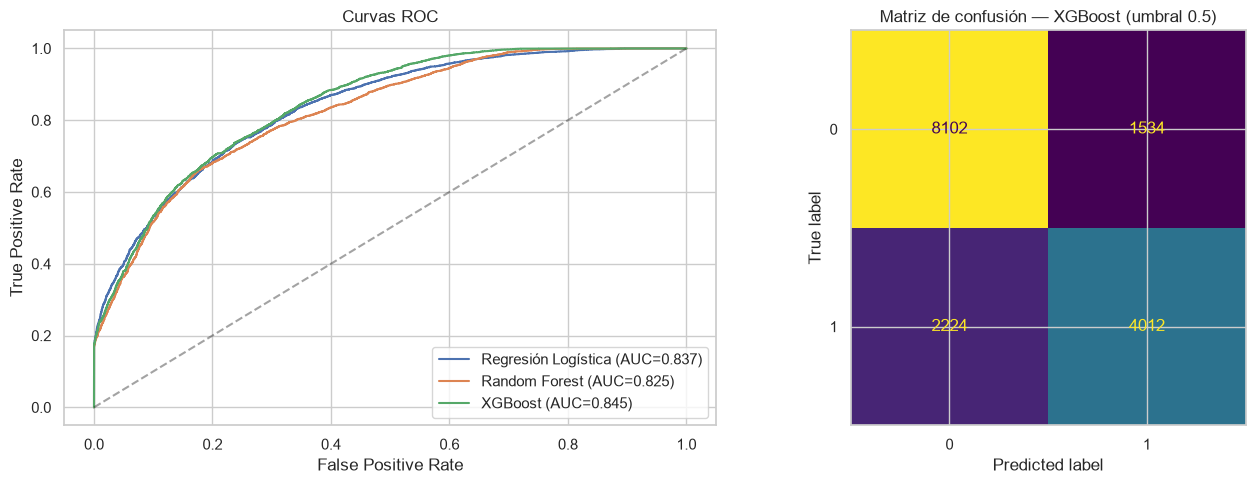

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for proba, label in [(proba_lr, "Regresión Logística"), (proba_rf, "Random Forest"), (proba_xgb, "XGBoost")]:
    fpr, tpr, _ = roc_curve(y_test, proba)
    axes[0].plot(fpr, tpr, label=f"{label} (AUC={roc_auc_score(y_test, proba):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.4)
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("Curvas ROC")
axes[0].legend()

ConfusionMatrixDisplay.from_predictions(y_test, pred_xgb, ax=axes[1], colorbar=False)
axes[1].set_title("Matriz de confusión — XGBoost (umbral 0.5)")

plt.tight_layout()
plt.show()


**Modelo ganador: XGBoost.** Supera al baseline y a Random Forest en AUC-ROC, que es la métrica más robusta ante el desbalanceo y no depende de un umbral fijo. A partir de aquí trabajamos con XGBoost.


### 10.1 Ajuste del umbral de decisión según coste de negocio

Como se planteó en la introducción, los dos tipos de error tienen coste distinto. Simulamos un escenario de coste ilustrativo:

- **Coste de un Falso Negativo** (cancelación no detectada → habitación vacía): asumimos ≈ 1 noche de ADR medio perdida.
- **Coste de un Falso Positivo** (acción preventiva innecesaria): asumimos un coste mucho menor, p. ej. el descuento ofrecido en un upgrade (≈ 15% del ADR medio).

Con estos supuestos (ajustables por el equipo de Revenue Management con datos reales de coste), buscamos el umbral que minimiza el coste total esperado en el conjunto de test.


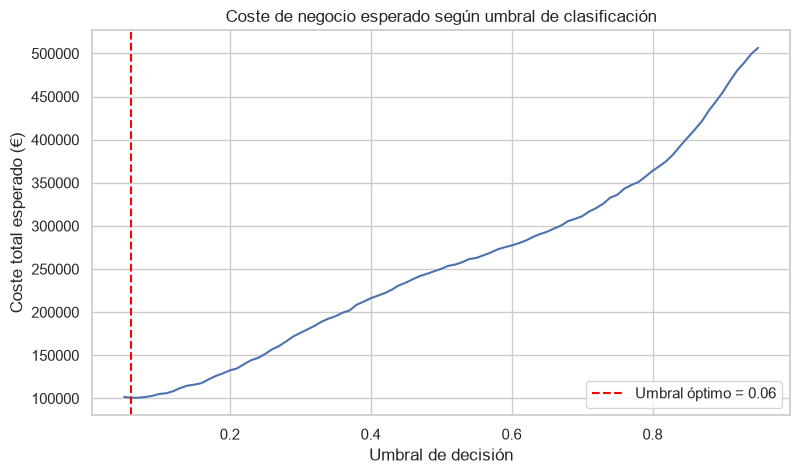

Umbral óptimo de negocio: 0.06 (vs. 0.50 por defecto)

Con umbral de negocio (0.06):
  Recall (cancelaciones detectadas): 0.985
  Precision:                         0.508
  F1-score:                          0.670


In [23]:
adr_medio = df["adr"].mean()
COSTE_FN = adr_medio           # habitación vacía ≈ 1 noche de ingreso perdido
COSTE_FP = 0.15 * adr_medio    # coste de una acción preventiva innecesaria (p.ej. descuento)

umbrales = np.linspace(0.05, 0.95, 91)
costes = []
for u in umbrales:
    pred_u = (proba_xgb >= u).astype(int)
    fn = ((pred_u == 0) & (y_test == 1)).sum()
    fp = ((pred_u == 1) & (y_test == 0)).sum()
    costes.append(fn * COSTE_FN + fp * COSTE_FP)

umbral_optimo = umbrales[np.argmin(costes)]

plt.figure()
plt.plot(umbrales, costes)
plt.axvline(umbral_optimo, color="red", linestyle="--", label=f"Umbral óptimo = {umbral_optimo:.2f}")
plt.xlabel("Umbral de decisión")
plt.ylabel("Coste total esperado (€)")
plt.title("Coste de negocio esperado según umbral de clasificación")
plt.legend()
plt.show()

print(f"Umbral óptimo de negocio: {umbral_optimo:.2f} (vs. 0.50 por defecto)")

pred_xgb_negocio = (proba_xgb >= umbral_optimo).astype(int)
print(f"\nCon umbral de negocio ({umbral_optimo:.2f}):")
print(f"  Recall (cancelaciones detectadas): {recall_score(y_test, pred_xgb_negocio):.3f}")
print(f"  Precision:                         {precision_score(y_test, pred_xgb_negocio):.3f}")
print(f"  F1-score:                          {f1_score(y_test, pred_xgb_negocio):.3f}")


**Conclusión de negocio:** dado que el coste de una habitación vacía es varias veces superior al de una acción preventiva de bajo impacto, el umbral óptimo se sitúa **muy por debajo de 0.5**, priorizando fuertemente el recall. De hecho, el óptimo matemático toca el extremo inferior del rango probado, lo que en la práctica equivaldría a marcar como "riesgo" a la inmensa mayoría de las reservas.

**Matización importante:** esto es una consecuencia esperable de minimizar un coste puramente económico sin restricciones operativas — Revenue Management no tiene capacidad para aplicar una acción preventiva (llamada, depósito, oferta) al 90% de las reservas. Un umbral único global no es la mejor forma de operacionalizar este modelo. Proponemos en su lugar un enfoque de **priorización por percentil de riesgo (targeting)**, mucho más realista operativamente.


### 10.2 Enfoque operativo alternativo: priorización por percentil de riesgo

En lugar de un umbral fijo, ordenamos las reservas de test por probabilidad de cancelación predicha y medimos qué porcentaje de las cancelaciones reales quedaría "capturado" si el equipo de Revenue Management solo pudiera actuar sobre el X% de reservas de mayor riesgo. Esto es lo que en la práctica permite dimensionar la operación (p. ej. "el equipo puede gestionar 200 reservas/semana con acción preventiva").


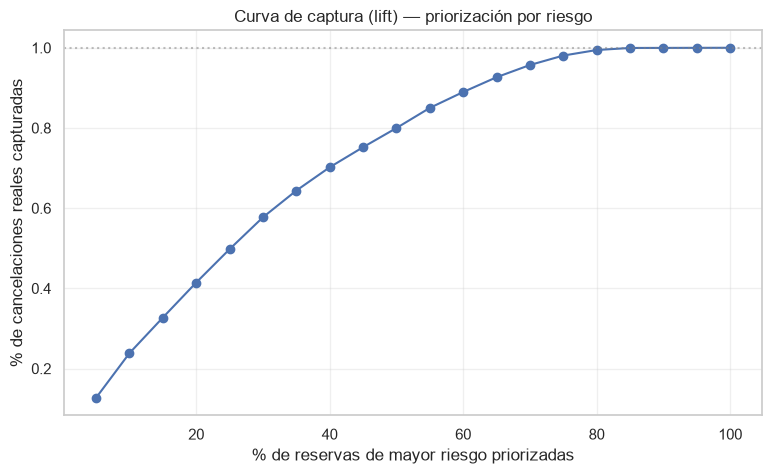

,% reservas priorizadas,% cancelaciones capturadas
0,5,12.7
1,10,23.8
2,15,32.7
3,20,41.5
4,25,49.8
5,30,57.7
6,35,64.4
7,40,70.2
8,45,75.2
9,50,80.0


In [24]:
orden = np.argsort(-proba_xgb)  # de mayor a menor riesgo
y_test_ordenado = y_test.values[orden]

percentiles = np.arange(5, 105, 5)
capturas = []
for p in percentiles:
    n = int(len(y_test_ordenado) * p / 100)
    capturas.append(y_test_ordenado[:n].sum() / y_test_ordenado.sum())

plt.figure()
plt.plot(percentiles, capturas, marker="o")
plt.axhline(1.0, color="gray", linestyle=":", alpha=0.5)
plt.xlabel("% de reservas de mayor riesgo priorizadas")
plt.ylabel("% de cancelaciones reales capturadas")
plt.title("Curva de captura (lift) — priorización por riesgo")
plt.grid(True, alpha=0.3)
plt.show()

tabla_captura = pd.DataFrame({
    "% reservas priorizadas": percentiles,
    "% cancelaciones capturadas": [round(c * 100, 1) for c in capturas]
})
tabla_captura


**Conclusión de negocio (targeting):** priorizando solo el **20-30% de reservas con mayor score de riesgo**, el equipo de Revenue Management ya captura una parte muy sustancial de las cancelaciones reales — muchísimo más eficiente que aplicar acciones preventivas de forma indiscriminada. Esta es la recomendación operativa final: usar el **score continuo del modelo para priorizar una lista de trabajo diaria/semanal**, dimensionada según la capacidad real del equipo, en lugar de un único umbral de decisión binario.


## 11. Interpretabilidad con SHAP

### 11.1 SHAP Summary Plot — importancia global de variables

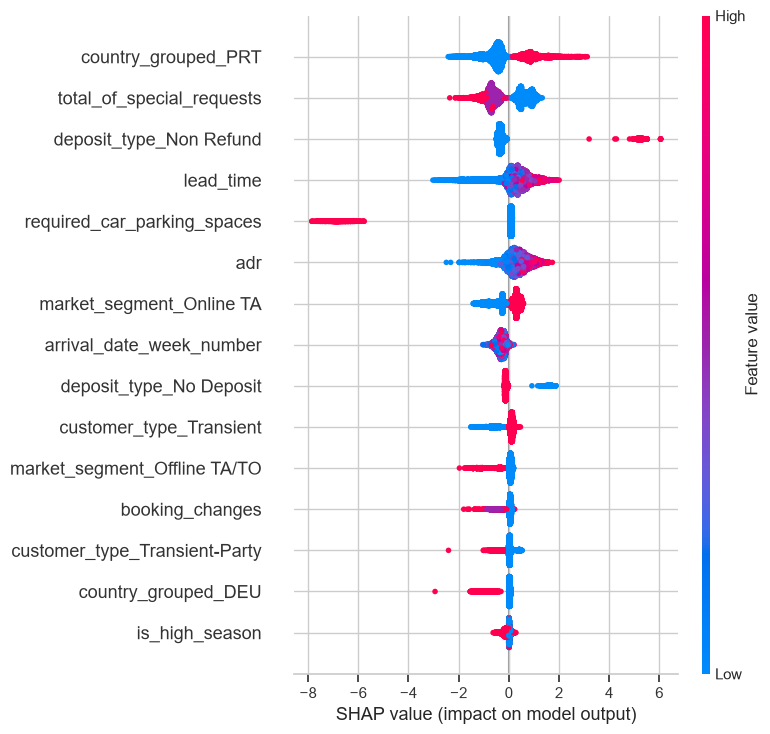

In [25]:
explainer = shap.TreeExplainer(xgb_best)
shap_values = explainer.shap_values(X_test_proc)

shap.summary_plot(
    shap_values, X_test_proc, feature_names=feature_names, show=False, max_display=15
)
plt.tight_layout()
plt.show()


**Lectura del summary plot:** las variables más influyentes son `country_grouped_PRT` (nacionalidad portuguesa), `total_of_special_requests`, `deposit_type_Non Refund`, `market_segment_Online TA`, `lead_time`, `required_car_parking_spaces` y `adr`.

Un hallazgo especialmente relevante —y a primera vista contraintuitivo— es que tener un depósito **"Non Refund"** (no reembolsable) es uno de los mayores impulsores hacia **mayor** probabilidad de cancelación, no menor. Esto es una peculiaridad ya documentada de este dataset: las reservas "Non Refund" suelen corresponder a bloqueos masivos de habitaciones por parte de agencias/mayoristas que después se cancelan en bloque, más que a clientes individuales comprometidos con una tarifa no reembolsable. Es un buen ejemplo de por qué la interpretabilidad importa: una regla de negocio ingenua ("depósito no reembolsable = cliente comprometido = bajo riesgo") sería errónea con estos datos.

Otras señales consistentes con el EDA: mayor `lead_time` y menor `total_of_special_requests` (bajo compromiso/personalización del viaje) aumentan el riesgo; en cambio, `required_car_parking_spaces` > 0 reduce fuertemente el riesgo predicho (un cliente que necesita aparcamiento está más comprometido logísticamente con la estancia).


### 11.2 SHAP Waterfall — dos reservas concretas

Elegimos dos casos ilustrativos: una reserva de **alto riesgo** (probabilidad predicha alta) y una reserva **"límite"**, cercana al umbral de decisión, para poder contar la historia de qué variables inclinan la balanza en cada caso.


In [26]:
idx_alto_riesgo = np.argmax(proba_xgb)
idx_limite = np.argmin(np.abs(proba_xgb - umbral_optimo))

print(f"Reserva de alto riesgo -> índice {idx_alto_riesgo}, probabilidad predicha = {proba_xgb[idx_alto_riesgo]:.3f}, real = {y_test.iloc[idx_alto_riesgo]}")
print(f"Reserva límite         -> índice {idx_limite}, probabilidad predicha = {proba_xgb[idx_limite]:.3f}, real = {y_test.iloc[idx_limite]}")


Reserva de alto riesgo -> índice 8346, probabilidad predicha = 1.000, real = 1
Reserva límite         -> índice 2358, probabilidad predicha = 0.060, real = 0


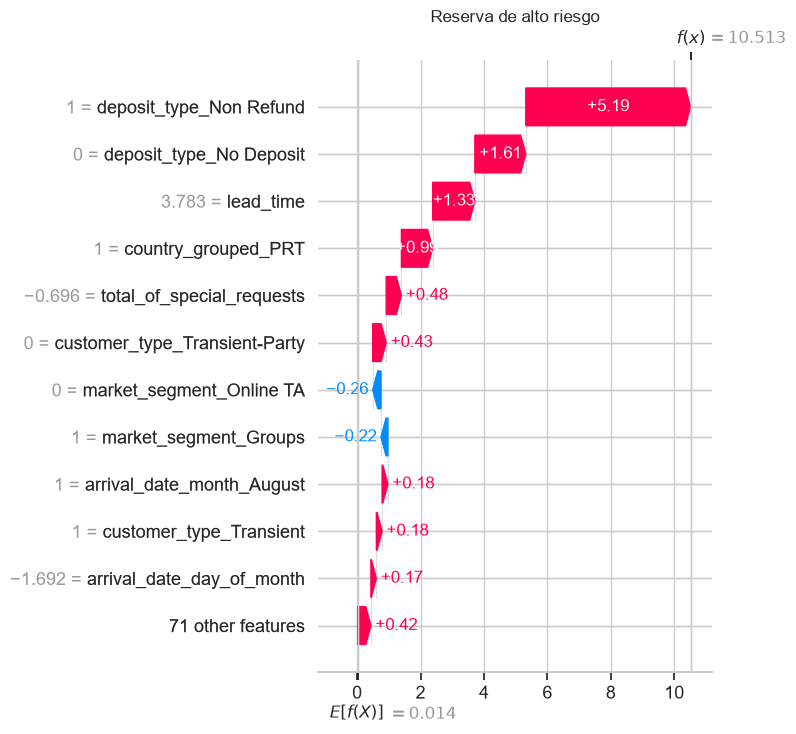

In [27]:
explanation = shap.Explanation(
    values=shap_values[idx_alto_riesgo],
    base_values=explainer.expected_value,
    data=X_test_proc[idx_alto_riesgo],
    feature_names=feature_names
)
shap.plots.waterfall(explanation, max_display=12, show=False)
plt.title("Reserva de alto riesgo")
plt.tight_layout()
plt.show()


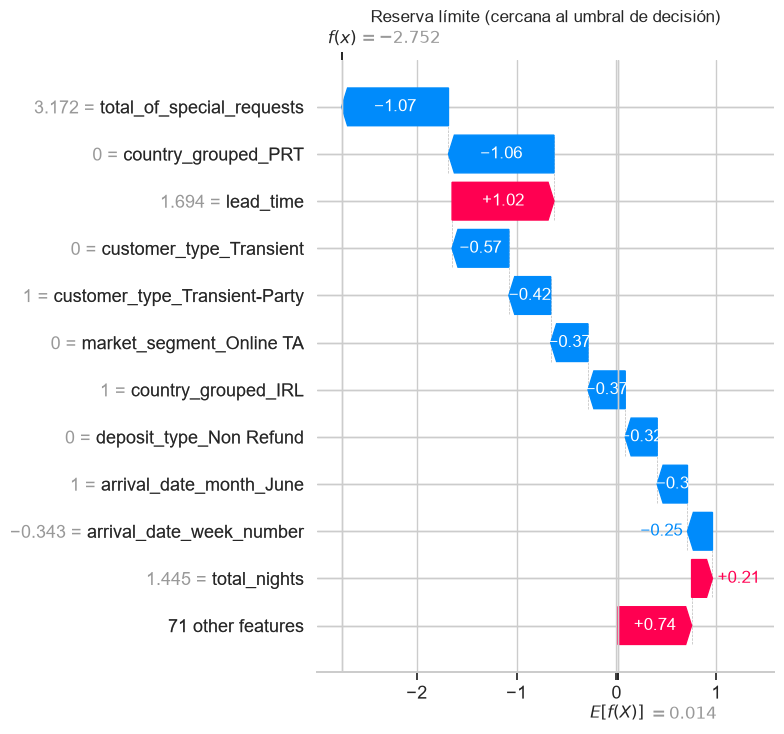

In [28]:
explanation_limite = shap.Explanation(
    values=shap_values[idx_limite],
    base_values=explainer.expected_value,
    data=X_test_proc[idx_limite],
    feature_names=feature_names
)
shap.plots.waterfall(explanation_limite, max_display=12, show=False)
plt.title("Reserva límite (cercana al umbral de decisión)")
plt.tight_layout()
plt.show()


**Conclusión de negocio (SHAP):** en la reserva de alto riesgo, el depósito "Non Refund" por sí solo explica la mayor parte del score (+4.96 en log-odds), reforzado por ser una reserva de origen portugués, con pocas peticiones especiales y alto lead_time. En la reserva "límite", un número alto de peticiones especiales (3 std. por encima de la media) compensa casi por completo el efecto de un lead_time elevado, arrastrando la probabilidad predicha muy cerca del umbral operativo. Esto justifica por qué el modelo aporta valor real frente a una regla simple tipo "antelación > X días": combina múltiples señales con pesos distintos y a veces contrapuestos.


## 12. Conclusiones

In [29]:
print('''
CONCLUSIONES DE NEGOCIO
========================

1. MODELO GANADOR
   XGBoost con hiperparámetros optimizados vía Optuna supera al baseline de
   Regresión Logística y a Random Forest en AUC-ROC, la métrica más robusta
   dado el desbalanceo de clases.

2. PERFIL DE RESERVA DE MAYOR RIESGO (según SHAP)
   - Depósito "Non Refund" (hallazgo contraintuitivo: en este dataset se
     asocia a bloqueos de agencias/grupos, no a clientes comprometidos)
   - Cliente de nacionalidad portuguesa (mercado local del hotel)
   - Captada vía Online TA más que canal directo
   - Alta antelación de la reserva (lead_time elevado)
   - Sin peticiones especiales (bajo "compromiso"/personalización del viaje)
   - Sin necesidad de plaza de parking
   - City Hotel por encima de Resort Hotel (según el EDA)

3. UMBRAL DE DECISIÓN Y OPERATIVA RECOMENDADA
   El coste de una habitación vacía supera holgadamente al de una acción
   preventiva de bajo impacto, por lo que el umbral matemáticamente óptimo
   tiende a marcar como riesgo a la mayoría de las reservas -> no es
   operativamente viable como umbral único. Recomendamos en su lugar
   PRIORIZAR POR PERCENTIL DE RIESGO: usar el score continuo del modelo
   para generar una lista de trabajo con el X% de reservas más críticas,
   dimensionada según la capacidad real del equipo de Revenue Management.

4. PROPUESTA DE ACCIÓN
   - Top 20-30% de reservas por score: contactar de forma proactiva para
     confirmar la estancia; si la reserva es directa/individual, valorar
     condiciones de depósito; si viene de agencia/grupo (el patrón "Non
     Refund" del dataset), renegociar con el intermediario las políticas
     de bloqueo y cancelación en origen.
   - Franja de riesgo medio: incentivar peticiones especiales / upgrades
     con descuento para aumentar el compromiso del cliente.
   - Ajustar la política de overbooking del City Hotel en los meses de
     temporada alta, donde la tasa de cancelación es mayor.

5. PRÓXIMOS PASOS
   - Recalibrar el coste de FN/FP con datos reales de Revenue Management
     en vez de la aproximación basada en ADR medio.
   - Monitorizar el modelo en producción y reentrenar periódicamente
     (drift estacional y de canal de distribución).
   - Explorar variables adicionales no presentes en este dataset (histórico
     de precios de la competencia, eventos locales, clima).
   - Evaluar un modelo específico por hotel si el volumen lo permite, dado
     que el comportamiento de cancelación difiere notablemente entre ambos.
''')



CONCLUSIONES DE NEGOCIO

1. MODELO GANADOR
   XGBoost con hiperparámetros optimizados vía Optuna supera al baseline de
   Regresión Logística y a Random Forest en AUC-ROC, la métrica más robusta
   dado el desbalanceo de clases.

2. PERFIL DE RESERVA DE MAYOR RIESGO (según SHAP)
   - Depósito "Non Refund" (hallazgo contraintuitivo: en este dataset se
     asocia a bloqueos de agencias/grupos, no a clientes comprometidos)
   - Cliente de nacionalidad portuguesa (mercado local del hotel)
   - Captada vía Online TA más que canal directo
   - Alta antelación de la reserva (lead_time elevado)
   - Sin peticiones especiales (bajo "compromiso"/personalización del viaje)
   - Sin necesidad de plaza de parking
   - City Hotel por encima de Resort Hotel (según el EDA)

3. UMBRAL DE DECISIÓN Y OPERATIVA RECOMENDADA
   El coste de una habitación vacía supera holgadamente al de una acción
   preventiva de bajo impacto, por lo que el umbral matemáticamente óptimo
   tiende a marcar como riesgo a la